# Intro to Pandas

In [191]:
!uv add pandas

Resolved 106 packages in 1ms
Checked 38 packages in 0.61ms


In [192]:
import pandas as pd

print(pd.__version__)

3.1.1


# Series
- **Series** : A Pandas 1-Dimensional labeled array that can hold any data type think of it like a single column in a spreadsheet (1-Dimensional)

In [193]:
data  = [100,102,104]

series = pd.Series(data)
print(series)
print()

data = ["A","B",100,True]
series = pd.Series(data)
print(series)
print(type(series[0]))
print(type(series[1]))
print(type(series[2]))
print(type(series[3]))
print(series)
print()

data = ["A","B","C"]
series = pd.Series(data)
print(series)

0    100
1    102
2    104
dtype: int64

0       A
1       B
2     100
3    True
dtype: object
<class 'str'>
<class 'str'>
<class 'int'>
<class 'bool'>
0       A
1       B
2     100
3    True
dtype: object

0    A
1    B
2    C
dtype: str


## Object Type
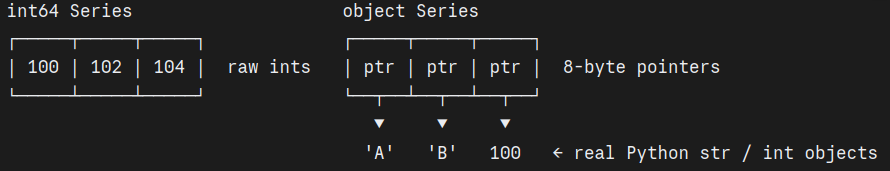

| Input | pandas 3.0 | NumPy default |
|---|---|---|
| [100, 102, 104] |	int64 (raw numbers) | int64 |
| ["A", "B", 100] | object (pointers, types kept) | <U21 (all converted to strings) |
| ["A", "B", "C"] | str (dedicated string type) | <U1 |

In [194]:
import numpy as np

arr = np.array(['A','B',100,True])
print(type(arr[2]),arr[2])
print(type(arr[3]),arr[3])
print(arr)

<class 'numpy.str_'> 100
<class 'numpy.str_'> True
['A' 'B' '100' 'True']


In [195]:
data = [100,102,104]
series = pd.Series(data, index=["a","b","c"])
print(series)
print(series.loc["a"])
print(series["b"])
print(series.iloc[2])
print()

data = [100,102,104,200,202]
series = pd.Series(data, index=["a","b","c","d","e"])
print(series[series < 200])
print()


a    100
b    102
c    104
dtype: int64
100
102
104

a    100
b    102
c    104
dtype: int64



In [196]:
calories = {"Day 1":1750, "Day 2": 2100, "Day 3":1700}
series = pd.Series(calories)
print(series)
print(series.loc["Day 1"])
print(series[series<2000])

Day 1    1750
Day 2    2100
Day 3    1700
dtype: int64
1750
Day 1    1750
Day 3    1700
dtype: int64


# DataFrames

- **DataFrames**: A tabular data structure with rows AND columns. (2 Dimensional) similar to an Excel spreadsheet

In [197]:
data = {
    "Name":["Spongebob","Patrick","Squidward"],
    "Age": [30,35,50],
}

df = pd.DataFrame(data)
print(df)
print()

df = pd.DataFrame(data, index=["Employee 1","Employee 2","Employee 3"])
print(df)
print()
print(df.loc["Employee 1"])
print(df.iloc[2])

        Name  Age
0  Spongebob   30
1    Patrick   35
2  Squidward   50

                 Name  Age
Employee 1  Spongebob   30
Employee 2    Patrick   35
Employee 3  Squidward   50

Name    Spongebob
Age            30
Name: Employee 1, dtype: object
Name    Squidward
Age            50
Name: Employee 3, dtype: object


In [198]:
# Add a new column
df["Job"] = ["Cook","N/A","Cashier"]
print(df)

                 Name  Age      Job
Employee 1  Spongebob   30     Cook
Employee 2    Patrick   35      N/A
Employee 3  Squidward   50  Cashier


In [199]:
# Add a new Row
# df = df.drop("Employee 4")
new_row = pd.DataFrame([
    {"Name": "Sandy", "Age": 28, "Job": "Engineer"},
    {"Name": "Eugene", "Age": 60, "Job": "Manager"}], 
index = ["Employee 4", "Employee 5"])
df = pd.concat([df,new_row])
print(df)

                 Name  Age       Job
Employee 1  Spongebob   30      Cook
Employee 2    Patrick   35       N/A
Employee 3  Squidward   50   Cashier
Employee 4      Sandy   28  Engineer
Employee 5     Eugene   60   Manager


# Importing

In [200]:
# df = pd.read_csv("./Dataset/data.csv")
df = pd.read_csv("./Dataset/data.csv",index_col="Name")
# data = pd.read_json()
print(df)
print(df.shape)
print(df.size)
print(df.ndim)
print(df.columns)
print("Number of Columns:",len(df.columns))

             No    Type1   Type2  Height  Weight  Legendary
Name                                                       
Bulbasaur     1    Grass  Poison     0.7     6.9          0
Ivysaur       2    Grass  Poison     1.0    13.0          0
Venusaur      3    Grass  Poison     2.0   100.0          0
Charmander    4     Fire     NaN     0.6     8.5          0
Charmeleon    5     Fire     NaN     1.1    19.0          0
...         ...      ...     ...     ...     ...        ...
Dragonite   149   Dragon  Flying     2.2   210.0          0
Mewtwo      150  Psychic     NaN     2.0   122.0          1
Snorlax     143   Normal     NaN     2.1   460.0          0
Snorlax     143   Normal     NaN     2.1   460.0          0
Snorlax     143   Normal     NaN     2.1   460.0          0

[153 rows x 6 columns]
(153, 6)
918
2
Index(['No', 'Type1', 'Type2', 'Height', 'Weight', 'Legendary'], dtype='str')
Number of Columns: 6


# Selection

In [201]:
# Selection By Column
# print(df["Name"])
print(df.index)
print(df[["Height","Weight"]])

Index(['Bulbasaur', 'Ivysaur', 'Venusaur', 'Charmander', 'Charmeleon',
       'Charizard', 'Squirtle', 'Wartortle', 'Blastoise', 'Caterpie',
       ...
       'Articuno', 'Zapdos', 'Moltres', 'Dratini', 'Dragonair', 'Dragonite',
       'Mewtwo', 'Snorlax', 'Snorlax', 'Snorlax'],
      dtype='str', name='Name', length=153)
            Height  Weight
Name                      
Bulbasaur      0.7     6.9
Ivysaur        1.0    13.0
Venusaur       2.0   100.0
Charmander     0.6     8.5
Charmeleon     1.1    19.0
...            ...     ...
Dragonite      2.2   210.0
Mewtwo         2.0   122.0
Snorlax        2.1   460.0
Snorlax        2.1   460.0
Snorlax        2.1   460.0

[153 rows x 2 columns]


In [202]:
# Selection By Row
# print(df.loc[0])

In [203]:
print(df.loc["Charizard",["Height","Weight"]])

Height     1.7
Weight    90.5
Name: Charizard, dtype: float64


In [204]:
# Slicing
print(df.loc["Charizard":"Blastoise",["Height","Weight"]])
print(df.iloc[0:11:2])

           Height  Weight
Name                     
Charizard     1.7    90.5
Squirtle      0.5     9.0
Wartortle     1.0    22.5
Blastoise     1.6    85.5
            No  Type1   Type2  Height  Weight  Legendary
Name                                                    
Bulbasaur    1  Grass  Poison     0.7     6.9          0
Venusaur     3  Grass  Poison     2.0   100.0          0
Charmeleon   5   Fire     NaN     1.1    19.0          0
Squirtle     7  Water     NaN     0.5     9.0          0
Blastoise    9  Water     NaN     1.6    85.5          0
Metapod     11    Bug     NaN     0.7     9.9          0


In [205]:
pokemon = input("Enter a Pokemon name:")
try:
    print(df.loc[pokemon])
except KeyError:
    print(f"{pokemon} not found")

No                 25
Type1        Electric
Type2             NaN
Height            0.4
Weight            6.0
Legendary           0
Name: Pikachu, dtype: object


# Filtering
- Keeping the rows that match a condition

In [206]:
tall_pokemon = df[df["Height"] >= 2]
print(tall_pokemon)

print()

heavy_pokemon = df[df["Weight"] > 100]
print(heavy_pokemon)

print()

legendary_pokemon = df[df["Legendary"] == True]
print(legendary_pokemon)

water_pokemon = df[(df["Type1"]=="Water") | (df["Type2"]=="Water")]
print(water_pokemon)

ff_pokemon = df[(df["Type1"]=="Fire") & (df["Type2"]=="Flying")]
print(ff_pokemon)

             No    Type1    Type2  Height  Weight  Legendary
Name                                                        
Venusaur      3    Grass   Poison     2.0   100.0          0
Ekans        23   Poison      NaN     2.0     6.9          0
Arbok        24   Poison      NaN     3.5    65.0          0
Onix         95     Rock   Ground     8.8   210.0          0
Exeggutor   103    Grass  Psychic     2.0   120.0          0
Kangaskhan  115   Normal      NaN     2.2    80.0          0
Gyarados    130    Water   Flying     6.5   235.0          0
Lapras      131    Water      Ice     2.5   220.0          0
Snorlax     143   Normal      NaN     2.1   460.0          0
Moltres     146     Fire   Flying     2.0    60.0          1
Dragonair   148   Dragon      NaN     4.0    16.5          0
Dragonite   149   Dragon   Flying     2.2   210.0          0
Mewtwo      150  Psychic      NaN     2.0   122.0          1
Snorlax     143   Normal      NaN     2.1   460.0          0
Snorlax     143   Normal

# Aggregation
- **aggregate functions** = Reduces a set of values into a single summary value Used to summarize and analyze data Often used with the groupyby() function

### Whole DataFrame

In [207]:
print(df.mean(numeric_only=True))

No           76.823529
Height        1.217647
Weight       54.344444
Legendary     0.026144
dtype: float64


In [208]:
print(df.sum(numeric_only=True))

No           11754.0
Height         186.3
Weight        8314.7
Legendary        4.0
dtype: float64


In [209]:
print(df.min(numeric_only=True))

No           1.0
Height       0.2
Weight       0.1
Legendary    0.0
dtype: float64


In [210]:
print(df.max(numeric_only=True))

No           150.0
Height         8.8
Weight       460.0
Legendary      1.0
dtype: float64


In [211]:
print(df.count())

No           153
Type1        153
Type2         67
Height       153
Weight       153
Legendary    153
dtype: int64


### Single Column

In [212]:
print(df["Height"].mean())

1.2176470588235295


In [213]:
print(df["Height"].sum())

186.3


In [214]:
print(df["Height"].min())

0.2


In [215]:
print(df["Height"].max())

8.8


In [216]:
print(df["Height"].count())

153


### Groupby

In [217]:
group = df.groupby("Type1")
print(group)

print()

print(group["Height"].mean())
print(group["Height"].sum())
print(group["Height"].min())
print(group["Height"].max())


Type1
Bug         0.900000
Dragon      2.666667
Electric    0.855556
Fairy       0.950000
Fighting    1.185714
Fire        1.216667
Ghost       1.466667
Grass       1.083333
Ground      0.850000
Ice         1.550000
Normal      1.120000
Poison      1.221429
Psychic     1.371429
Rock        1.844444
Water       1.300000
Name: Height, dtype: float64
Type1
Bug         10.8
Dragon       8.0
Electric     7.7
Fairy        1.9
Fighting     8.3
Fire        14.6
Ghost        4.4
Grass       13.0
Ground       6.8
Ice          3.1
Normal      28.0
Poison      17.1
Psychic      9.6
Rock        16.6
Water       36.4
Name: Height, dtype: float64
Type1
Bug         0.3
Dragon      1.8
Electric    0.3
Fairy       0.6
Fighting    0.5
Fire        0.6
Ghost       1.3
Grass       0.4
Ground      0.2
Ice         1.4
Normal      0.3
Poison      0.4
Psychic     0.9
Rock        0.4
Water       0.3
Name: Height, dtype: float64
Type1
Bug         1.5
Dragon      4.0
Electric    1.6
Fairy       1.3
Fighting    1.

# Data Cleaning
- **Data Cleaning** = The process of fixing/removing: incomplete, incorrect, or irrelevant data. ~75% of work done with pandas is data cleaning.

In [218]:
df_temp = pd.read_csv("./Dataset/data.csv")

In [219]:
# 1. Drop irrelevant columns
df = df_temp
df = df.drop(columns=["No"])
print(df)

           Name    Type1   Type2  Height  Weight  Legendary
0     Bulbasaur    Grass  Poison     0.7     6.9          0
1       Ivysaur    Grass  Poison     1.0    13.0          0
2      Venusaur    Grass  Poison     2.0   100.0          0
3    Charmander     Fire     NaN     0.6     8.5          0
4    Charmeleon     Fire     NaN     1.1    19.0          0
..          ...      ...     ...     ...     ...        ...
148   Dragonite   Dragon  Flying     2.2   210.0          0
149      Mewtwo  Psychic     NaN     2.0   122.0          1
150     Snorlax   Normal     NaN     2.1   460.0          0
151     Snorlax   Normal     NaN     2.1   460.0          0
152     Snorlax   Normal     NaN     2.1   460.0          0

[153 rows x 6 columns]


In [220]:
# 2. Handle missing data
df = df_temp
df = df.dropna(subset=["Type2"])
print(df)
print(df.count())

      No        Name     Type1   Type2  Height  Weight  Legendary
0      1   Bulbasaur     Grass  Poison     0.7     6.9          0
1      2     Ivysaur     Grass  Poison     1.0    13.0          0
2      3    Venusaur     Grass  Poison     2.0   100.0          0
5      6   Charizard      Fire  Flying     1.7    90.5          0
11    12  Butterfree       Bug  Flying     1.1    32.0          0
..   ...         ...       ...     ...     ...     ...        ...
141  142  Aerodactyl      Rock  Flying     1.8    59.0          0
143  144    Articuno       Ice  Flying     1.7    55.4          1
144  145      Zapdos  Electric  Flying     1.6    52.6          1
145  146     Moltres      Fire  Flying     2.0    60.0          1
148  149   Dragonite    Dragon  Flying     2.2   210.0          0

[67 rows x 7 columns]
No           67
Name         67
Type1        67
Type2        67
Height       67
Weight       67
Legendary    67
dtype: int64


In [221]:
df = df_temp
df = df.fillna({"Type2":"None"})
print(df)
print(df.count())

      No        Name    Type1   Type2  Height  Weight  Legendary
0      1   Bulbasaur    Grass  Poison     0.7     6.9          0
1      2     Ivysaur    Grass  Poison     1.0    13.0          0
2      3    Venusaur    Grass  Poison     2.0   100.0          0
3      4  Charmander     Fire    None     0.6     8.5          0
4      5  Charmeleon     Fire    None     1.1    19.0          0
..   ...         ...      ...     ...     ...     ...        ...
148  149   Dragonite   Dragon  Flying     2.2   210.0          0
149  150      Mewtwo  Psychic    None     2.0   122.0          1
150  143     Snorlax   Normal    None     2.1   460.0          0
151  143     Snorlax   Normal    None     2.1   460.0          0
152  143     Snorlax   Normal    None     2.1   460.0          0

[153 rows x 7 columns]
No           153
Name         153
Type1        153
Type2        153
Height       153
Weight       153
Legendary    153
dtype: int64


In [222]:
# 3. Fix inconsistent values
df = df_temp
df["Type1"] = df["Type1"].replace({
    "Grass":"GRASS",
    "Fire":"FIRE",
    "Water":"WATER"
})
print(df)

      No        Name    Type1   Type2  Height  Weight  Legendary
0      1   Bulbasaur    GRASS  Poison     0.7     6.9          0
1      2     Ivysaur    GRASS  Poison     1.0    13.0          0
2      3    Venusaur    GRASS  Poison     2.0   100.0          0
3      4  Charmander     FIRE     NaN     0.6     8.5          0
4      5  Charmeleon     FIRE     NaN     1.1    19.0          0
..   ...         ...      ...     ...     ...     ...        ...
148  149   Dragonite   Dragon  Flying     2.2   210.0          0
149  150      Mewtwo  Psychic     NaN     2.0   122.0          1
150  143     Snorlax   Normal     NaN     2.1   460.0          0
151  143     Snorlax   Normal     NaN     2.1   460.0          0
152  143     Snorlax   Normal     NaN     2.1   460.0          0

[153 rows x 7 columns]


In [223]:
# 4. Standardize text
df["Name"] = df["Name"].str.lower()
print(df)

      No        Name    Type1   Type2  Height  Weight  Legendary
0      1   bulbasaur    GRASS  Poison     0.7     6.9          0
1      2     ivysaur    GRASS  Poison     1.0    13.0          0
2      3    venusaur    GRASS  Poison     2.0   100.0          0
3      4  charmander     FIRE     NaN     0.6     8.5          0
4      5  charmeleon     FIRE     NaN     1.1    19.0          0
..   ...         ...      ...     ...     ...     ...        ...
148  149   dragonite   Dragon  Flying     2.2   210.0          0
149  150      mewtwo  Psychic     NaN     2.0   122.0          1
150  143     snorlax   Normal     NaN     2.1   460.0          0
151  143     snorlax   Normal     NaN     2.1   460.0          0
152  143     snorlax   Normal     NaN     2.1   460.0          0

[153 rows x 7 columns]


In [224]:
# 5. Fix data types
df["Legendary"] = df["Legendary"].astype(bool)
print(df)

      No        Name    Type1   Type2  Height  Weight  Legendary
0      1   bulbasaur    GRASS  Poison     0.7     6.9      False
1      2     ivysaur    GRASS  Poison     1.0    13.0      False
2      3    venusaur    GRASS  Poison     2.0   100.0      False
3      4  charmander     FIRE     NaN     0.6     8.5      False
4      5  charmeleon     FIRE     NaN     1.1    19.0      False
..   ...         ...      ...     ...     ...     ...        ...
148  149   dragonite   Dragon  Flying     2.2   210.0      False
149  150      mewtwo  Psychic     NaN     2.0   122.0       True
150  143     snorlax   Normal     NaN     2.1   460.0      False
151  143     snorlax   Normal     NaN     2.1   460.0      False
152  143     snorlax   Normal     NaN     2.1   460.0      False

[153 rows x 7 columns]


In [228]:
# 6. Duplicate Values
print(df.duplicated().mean()*100)
df = df.drop_duplicates()
print(df.duplicated().mean()*100)

1.9607843137254901
0.0
